<a href="https://colab.research.google.com/github/bagussyahputra041104-gif/ILP-Simulator/blob/main/ILP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Simulator from https://github.com/harshitasingh4863/instruction-level-parallelism-simulator.git

from dataclasses import dataclass


@dataclass
class Instruction:
    name: str
    destination: str
    sources: list


# -------------------------------------------------
# Sample Instruction Set
# -------------------------------------------------

instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R4", ["R5", "R6"]),
    Instruction("I3", "R7", ["R1", "R4"]),
    Instruction("I4", "R8", ["R9", "R10"]),
    Instruction("I5", "R11", ["R7", "R8"]),
    Instruction("I6", "R12", ["R13", "R14"]),
]


# -------------------------------------------------
# Function to check dependency
# -------------------------------------------------

def has_dependency(inst1, inst2):
    """
    Returns True if inst2 depends on inst1.
    """

    # RAW dependency:
    # inst2 reads a register written by inst1
    if inst1.destination in inst2.sources:
        return True

    return False


# -------------------------------------------------
# Sequential Execution
# -------------------------------------------------

def sequential_execution(instructions):
    print("\n" + "=" * 50)
    print("SEQUENTIAL EXECUTION")
    print("=" * 50)

    cycle = 0

    for instruction in instructions:
        cycle += 1

        print(
            f"Cycle {cycle}: Executing {instruction.name} "
            f"({instruction.destination} = "
            f"{' + '.join(instruction.sources)})"
        )

    print(f"\nTotal Sequential Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# ILP / Parallel Execution
# -------------------------------------------------

def parallel_execution(instructions):
    print("\n" + "=" * 50)
    print("INSTRUCTION-LEVEL PARALLEL EXECUTION")
    print("=" * 50)

    completed = set()
    remaining = instructions.copy()

    cycle = 0

    while remaining:

        cycle += 1
        current_cycle = []

        for instruction in remaining:

            # Check whether all previous dependencies
            # have already been completed

            dependencies_satisfied = True

            for previous in instructions:

                if previous.name == instruction.name:
                    break

                if has_dependency(previous, instruction):
                    if previous.name not in completed:
                        dependencies_satisfied = False
                        break

            if dependencies_satisfied:
                current_cycle.append(instruction)

        # Execute all independent instructions
        # in the same cycle

        print(f"\nCycle {cycle}:")

        for instruction in current_cycle:
            print(
                f"  -> {instruction.name}: "
                f"{instruction.destination} = "
                f"{' + '.join(instruction.sources)}"
            )

        # Mark instructions as completed

        for instruction in current_cycle:
            completed.add(instruction.name)
            remaining.remove(instruction)

    print(f"\nTotal ILP Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# Dependency Analysis
# -------------------------------------------------

def show_dependencies(instructions):

    print("\n" + "=" * 50)
    print("DEPENDENCY ANALYSIS")
    print("=" * 50)

    found = False

    for i in range(len(instructions)):

        for j in range(i + 1, len(instructions)):

            if has_dependency(instructions[i], instructions[j]):

                print(
                    f"{instructions[j].name} depends on "
                    f"{instructions[i].name} "
                    f"(Register: {instructions[i].destination})"
                )

                found = True

    if not found:
        print("No dependencies found.")


# -------------------------------------------------
# Main Program
# -------------------------------------------------

def main():

    print("\n")
    print("*" * 60)
    print("      INSTRUCTION-LEVEL PARALLELISM SIMULATOR")
    print("*" * 60)

    print("\nInstruction Set:")

    for instruction in instructions:
        print(
            f"{instruction.name}: "
            f"{instruction.destination} = "
            f"{' + '.join(instruction.sources)}"
        )

    # Show dependencies

    show_dependencies(instructions)

    # Sequential execution

    sequential_cycles = sequential_execution(instructions)

    # Parallel execution

    parallel_cycles = parallel_execution(instructions)

    # Calculate speedup

    speedup = sequential_cycles / parallel_cycles

    efficiency = speedup / len(instructions) * 100

    print("\n" + "=" * 50)
    print("PERFORMANCE COMPARISON")
    print("=" * 50)

    print(f"Sequential Cycles : {sequential_cycles}")
    print(f"ILP Cycles        : {parallel_cycles}")
    print(f"Speedup            : {speedup:.2f}x")
    print(f"ILP Efficiency     : {efficiency:.2f}%")

    print("\nConclusion:")
    print(
        "ILP reduces execution cycles by allowing "
        "independent instructions to execute in parallel."
    )


# -------------------------------------------------
# Run Program
# -------------------------------------------------

if __name__ == "__main__":
    main()




************************************************************
      INSTRUCTION-LEVEL PARALLELISM SIMULATOR
************************************************************

Instruction Set:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R7 = R1 + R4
I4: R8 = R9 + R10
I5: R11 = R7 + R8
I6: R12 = R13 + R14

DEPENDENCY ANALYSIS
I3 depends on I1 (Register: R1)
I3 depends on I2 (Register: R4)
I5 depends on I3 (Register: R7)
I5 depends on I4 (Register: R8)

SEQUENTIAL EXECUTION
Cycle 1: Executing I1 (R1 = R2 + R3)
Cycle 2: Executing I2 (R4 = R5 + R6)
Cycle 3: Executing I3 (R7 = R1 + R4)
Cycle 4: Executing I4 (R8 = R9 + R10)
Cycle 5: Executing I5 (R11 = R7 + R8)
Cycle 6: Executing I6 (R12 = R13 + R14)

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I2: R4 = R5 + R6
  -> I4: R8 = R9 + R10
  -> I6: R12 = R13 + R14

Cycle 2:
  -> I3: R7 = R1 + R4

Cycle 3:
  -> I5: R11 = R7 + R8

Total ILP Cycles: 3

PERFORMANCE COMPARISON
Sequential Cycles : 6
ILP Cyc

In [ ]:
ANDHARA BAGIAN RAW

In [1]:
from dataclasses import dataclass
import networkx as nx
import matplotlib.pyplot as plt

print("Library berhasil diimport!")

Library berhasil diimport!


In [2]:
@dataclass
class Instruction:
    name: str
    destination: str
    sources: list


instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R4", ["R1", "R5"]),
    Instruction("I3", "R6", ["R4", "R7"]),
    Instruction("I4", "R8", ["R9", "R10"]),
]

print("=== INSTRUCTION SET ===")

for inst in instructions:
    print(
        f"{inst.name}: {inst.destination} = "
        f"{' + '.join(inst.sources)}"
    )

=== INSTRUCTION SET ===
I1: R1 = R2 + R3
I2: R4 = R1 + R5
I3: R6 = R4 + R7
I4: R8 = R9 + R10


In [3]:
def find_raw_dependencies(instructions):
    raw_dependencies = []

    for i in range(len(instructions)):
        for j in range(i + 1, len(instructions)):
            first = instructions[i]
            second = instructions[j]

            # RAW terjadi jika instruksi berikutnya
            # membaca register yang ditulis sebelumnya.
            for register in first.destination.split():
                if register in second.sources:
                    raw_dependencies.append({
                        "source": first.name,
                        "target": second.name,
                        "register": register,
                        "type": "RAW"
                    })

    return raw_dependencies


raw_dependencies = find_raw_dependencies(instructions)

print("=== RAW DEPENDENCY ANALYSIS ===")

if raw_dependencies:
    for dep in raw_dependencies:
        print(
            f"{dep['source']} -> {dep['target']} "
            f"(RAW pada {dep['register']})"
        )
else:
    print("Tidak ditemukan RAW dependency.")

=== RAW DEPENDENCY ANALYSIS ===
I1 -> I2 (RAW pada R1)
I2 -> I3 (RAW pada R4)


In [4]:
print("=== RAW DEPENDENCY TABLE ===")
print()

print(
    f"{'Source':<10} {'Target':<10} "
    f"{'Register':<10} {'Type':<10}"
)
print("-" * 40)

for dep in raw_dependencies:
    print(
        f"{dep['source']:<10} "
        f"{dep['target']:<10} "
        f"{dep['register']:<10} "
        f"{dep['type']:<10}"
    )

=== RAW DEPENDENCY TABLE ===

Source     Target     Register   Type      
----------------------------------------
I1         I2         R1         RAW       
I2         I3         R4         RAW       


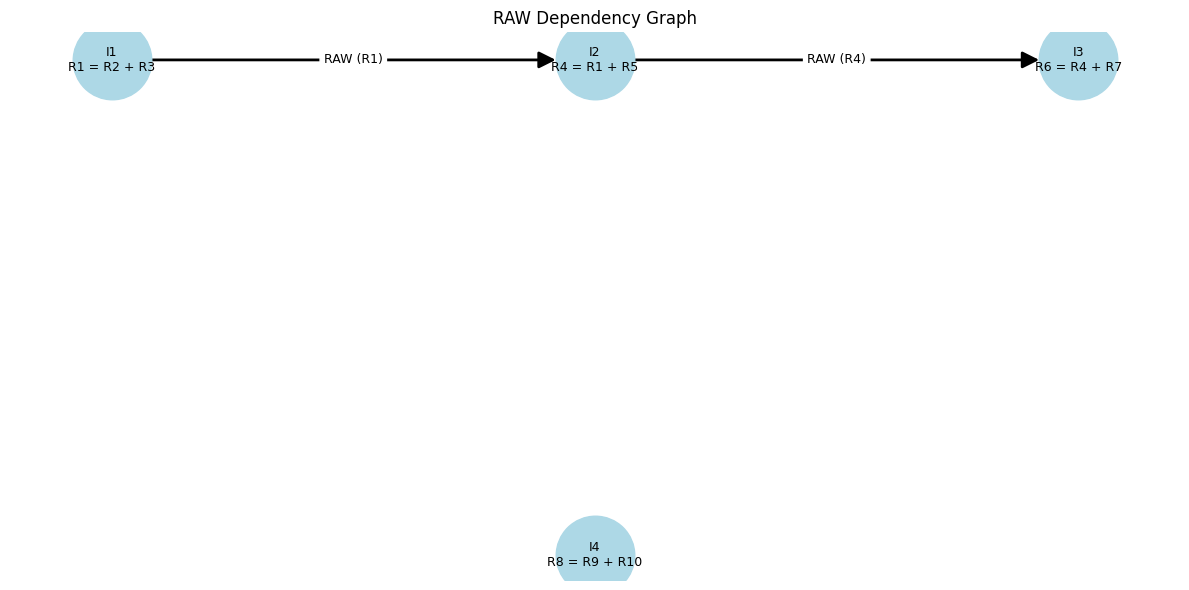

In [5]:
G = nx.DiGraph()

# Menambahkan semua instruksi sebagai node.
for inst in instructions:
    G.add_node(inst.name)

# Menambahkan hubungan RAW sebagai edge.
for dep in raw_dependencies:
    G.add_edge(
        dep["source"],
        dep["target"],
        label=f"RAW ({dep['register']})"
    )

# Posisi node agar mudah dibaca.
pos = {
    "I1": (0, 1),
    "I2": (2, 1),
    "I3": (4, 1),
    "I4": (2, -1)
}

labels = {
    inst.name: (
        f"{inst.name}\n"
        f"{inst.destination} = {' + '.join(inst.sources)}"
    )
    for inst in instructions
}

plt.figure(figsize=(12, 6))

nx.draw_networkx_nodes(
    G, pos,
    node_size=3200,
    node_color="lightblue"
)

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=9
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=25,
    node_size=3200,
    edge_color="black",
    width=2
)

edge_labels = nx.get_edge_attributes(G, "label")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("RAW Dependency Graph")
plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
print("=" * 45)
print("RAW DEPENDENCY SUMMARY")
print("=" * 45)

print(f"Total instruksi      : {len(instructions)}")
print(f"Total RAW dependency: {len(raw_dependencies)}")

print("\nDependency yang ditemukan:")

for dep in raw_dependencies:
    print(
        f"- {dep['source']} -> {dep['target']} "
        f"pada register {dep['register']}"
    )

RAW DEPENDENCY SUMMARY
Total instruksi      : 4
Total RAW dependency: 2

Dependency yang ditemukan:
- I1 -> I2 pada register R1
- I2 -> I3 pada register R4


In [7]:
import pandas as pd
from IPython.display import display

df_raw = pd.DataFrame(raw_dependencies)

if not df_raw.empty:
    df_raw = df_raw.rename(columns={
        "source": "Source",
        "target": "Target",
        "register": "Register",
        "type": "Type"
    })

    display(df_raw)
else:
    print("Tidak ditemukan RAW dependency.")

,Source,Target,Register,Type
0,I1,I2,R1,RAW
1,I2,I3,R4,RAW
